### Perceptron

In [2]:
import numpy as np
import matplotlib.pyplot as plt

### Implementação do Perceptron

In [20]:
class Perceptron:
    def __init__(self, learning_rate=0.01, n_epochs=1000, weight_init="random"):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.weights = None
        self.weight_init = weight_init
        self.bias = None
        self.errors_per_epoch = [] # Armazena o erro a cada época

    # Inicializando os pesos de forma customizada
    def _initialize_weights(self, n_features):
        """ Inicializa os pesos de acordo com o método escolhido """
        if self.weight_init == "random":
            self.weights = np.random.rand(n_features)
            self.bias = np.random.rand()
        elif self.weight_init == "zeros":
            self.weights = np.zeros(n_features)
            self.bias = 0
        elif self.weight_init == "normal":
            self.weights == np.random.randn(n_features) * 0.01 # Pequenos valores gaussianos
            self.bias = np.random.randn() * 0.01
        else:
            raise ValueError("Opção inválida para inicialização dos pesos")

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self._initialize_weights(n_features) # Inicializa os pesos dinamicamente
        self.bias = 0

        for epoch in range(self.n_epochs):
            errors = 0 # Contador de erros por época

            for i in range(n_samples):
                linear_output = np.dot(X[i], self.weights) + self.bias
                y_pred = np.sign(linear_output)

                # Atualização dos pesos se houver erro
                if y_pred != y[i]:
                    self.weights += self.learning_rate * y[i] * X[i]
                    self.bias += self.learning_rate * y[i]
                    errors += 1 # Incrementa erro se classificação errada

            # Armazena a taxa de erro (erros / total de amostras)
            self.errors_per_epoch.append(errors / n_samples)

            # Parada antecipada se não houver erros
            if errors == 0:
                break
        
        # Após o treinamento, calcular e exibir as estatísticas
        self._print_training_summary(X, y, epoch + 1)

    # Método para exibir a acurácia e pesos finais
    def _print_training_summary(self, X, y, epochs):
        y_pred = self.predict(X)
        accuracy = np.mean(y_pred == y) * 100
        std_dev = np.std(self.weights)

        print("\n===== Resumo do Treinamento =====")
        print(f"Acurácia no conjunto de treino: {accuracy:.2f}%")
        print(f"Número total de épocas: {epochs}")
        print(f"Pesos finais aprendidos: {self.weights}")
        print(f"Bias Final: {self.bias}")
        print("==============================================\n")

    # Retorna a predição com base no treinamento do Perceptron
    def predict(self, X):
        return np.sign(np.dot(X, self.weights) + self.bias)

    # Faz previsões e, se os rótulos forem fornecidos, exibe métricas
    def predict2(self, X, y, y_true=None):
        y_pred = np.sign(np.dot(X, self.weights) + self.bias)

        # Se y_true for fornecido, calcular métricas de avaliação
        if y_true is not None:
            self.predict_summary(X, y_true, 0, "Teste")
        
        return y_pred

    # Calculando as métricas de predição
    def predict_summary(self, X, y, epochs, phase):
        """ Método para exibir a acurácia, desvio padrão e pesos finais """
        y_pred = np.sign(np.dot(X, self.weights) + self.bias)
        accuracy = np.mean(y_pred == y) * 100
        std_dev = np.std(self.weights)

        print(f"\n===== Resumo do {phase} =====")
        print(f"Acurácia no conjunto de {phase.lower()}: {accuracy:.2f}%")
        print(f"Desvio Padrão dos Pesos: {std_dev:.5f}")
        if epochs > 0:
            print(f"Número total de épocas: {epochs}")
        print(f"Pesos finais aprendidos: {self.weights}")
        print(f"Bias final: {self.bias}")
        print("==============================================\n")

    # Plota o gráfico da evolução dos erros ao longo das épocas de treinamento
    def plot_error(self):
        plt.figure(figsize=(8, 4))
        plt.plot(self.errors_per_epoch, marker='o', linestyle='-')
        plt.xlabel("Época")
        plt.ylabel("Evolução do erro ao longo das épocas")
        plt.grid()
        plt.show()

In [21]:
# Gráfico da "fronteira" gerado pelo Perceptron
def plot_decision_boundary(X, y, model, title="Fronteira de Decisão do Perceptron"):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Criar o gráfico
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title(title)
    plt.show()

In [22]:
# Função para plotar lado a lado: dataset e fronteira de decisão
def plot_comparision(X, y, model):
    # Criar uma grade para o plano cartesiano
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Criar os subplots (1 linha, 2 colunas)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Subplot 1 - Fronteira de Decisão
    axes[0].contourf(xx, yy, Z, alpha=0.3)
    axes[0].scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    axes[0].set_xlabel("X1")
    axes[0].set_ylabel("X2")
    axes[0].set_title("Fronteira de Decisão do Perceptron")

     # Subplot 1 - Fronteira de Decisão
    axes[1].scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    axes[1].set_xlabel("X1")
    axes[1].set_ylabel("X2")
    axes[1].set_title("Distribuição dos dados do dataset")

    plt.tight_layout()
    plt.show()

### DATASET 1 - TREINO


===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 97.86%
Número total de épocas: 100
Pesos finais aprendidos: [-0.78965388  0.67914075]
Bias Final: 0.4



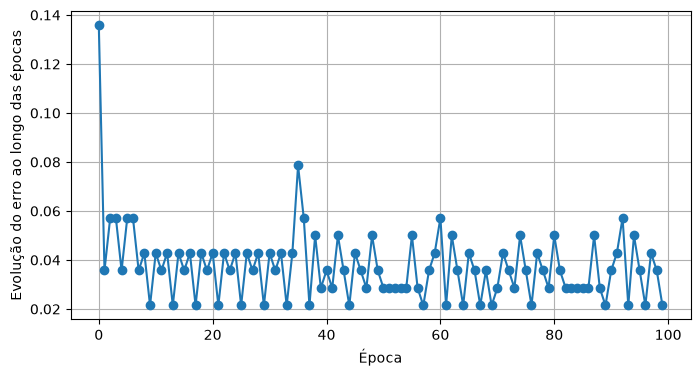

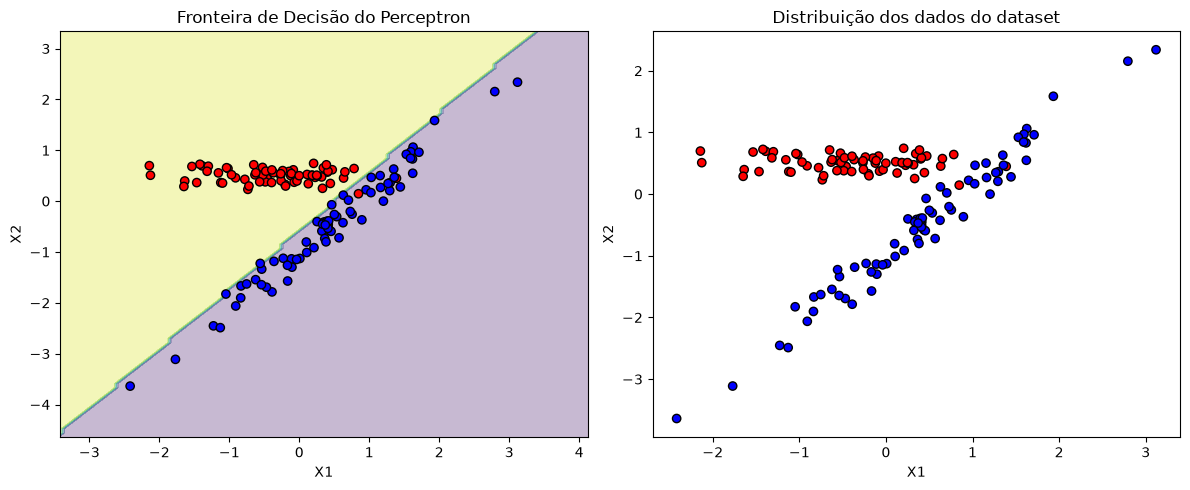

In [28]:
# Dataset 1 - Importando e visualizando o dataset de TREINO
train_dataset1 = np.loadtxt("train_dataset1.csv", delimiter=",", skiprows=1, dtype=float)

# Definição das entradas
X = train_dataset1[: , :2] # As duas primeiras colunas são os atributos (X1 e X2)
y = train_dataset1[:, 2] # Terceira coluna (rótulos)

# Converter rótulos para -1 e 1 (caso estejam diferentes)
y = np.where(y == -1, -1, 1)

# Criação do Perceptron e definição da taxa de aprendizado como 0.1 e número de épocas em 100
perceptron = Perceptron(learning_rate=0.1, n_epochs=100)

# Treinamento do Perceptron
perceptron.fit(X, y)

# Fazer previsões
y_pred = perceptron.predict2(X, y)

# Plotar a evolução do erro
perceptron.plot_error()

print("")

# Plot dos gráficos lado a lado
plot_comparision(X, y, perceptron)

### DATASET 1 - TESTE


===== Resumo do Teste =====
Acurácia no conjunto de teste: 95.00%
Desvio Padrão dos Pesos: 0.73440
Pesos finais aprendidos: [-0.78965388  0.67914075]
Bias final: 0.4



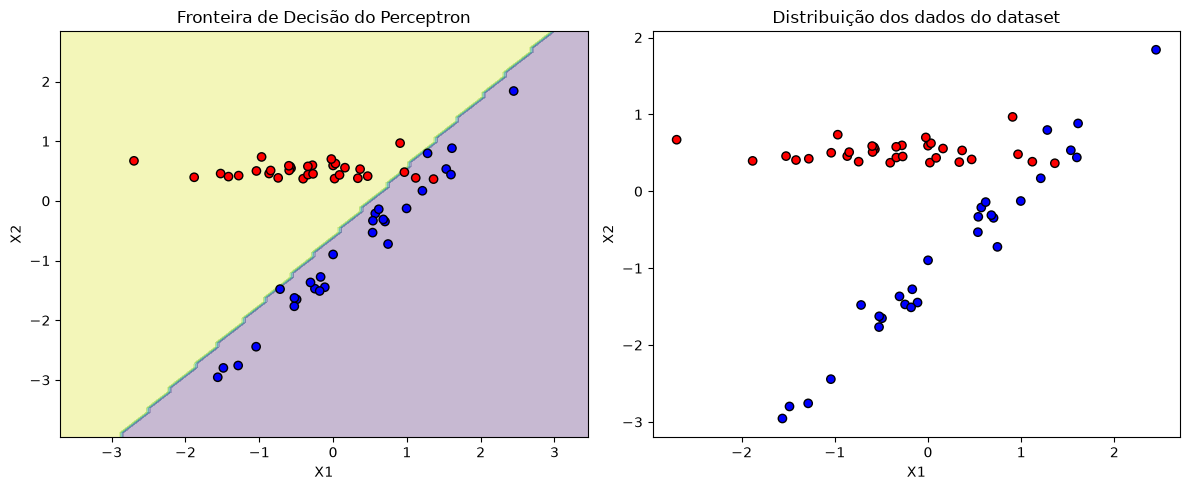

In [35]:
# Dataset 1 - Importando e visualizando o dataset de TESTE
test_dataset1 = np.loadtxt("test_dataset1.csv", delimiter=",", skiprows=1, dtype=float)

# Definição das entradas
X_test = test_dataset1[: , :2] # As duas primeiras colunas são os atributos (X1 e X2)
y_test = test_dataset1[:, 2] # Terceira coluna (rótulos)

# Converter rótulos para -1 e 1 (caso estejam diferentes)
y_test = np.where(y_test == -1, -1, 1)

# Fazer previsões
perceptron.predict2(X_test, y, y_test)

# Plot dos gráficos lado a lado
plot_comparision(X_test, y_test, perceptron)

### DATASET 2 - TREINO


===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 44.57%
Número total de épocas: 100
Pesos finais aprendidos: [0.07286498 0.00122305]
Bias Final: -2.7755575615628914e-17



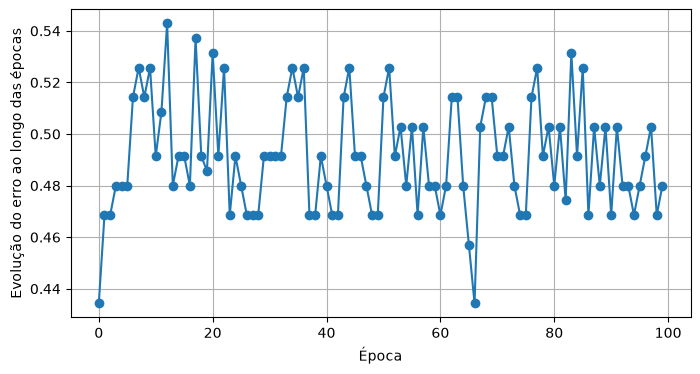

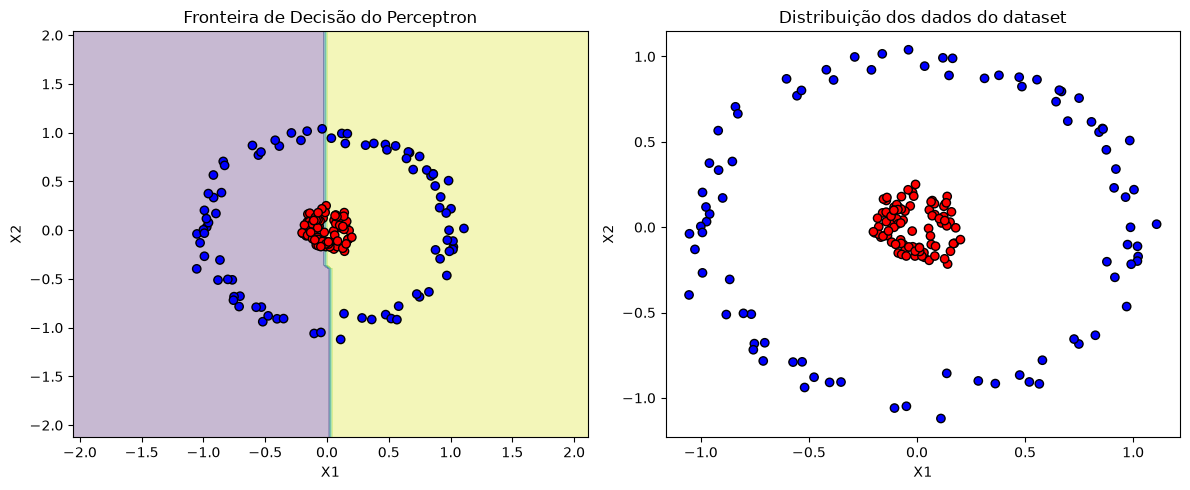

In [36]:
# Dataset 2 - Importando e visualizando o dataset de TREINO
train_dataset2 = np.loadtxt("train_dataset2.csv", delimiter=",", skiprows=1, dtype=float)

# Definição das entradas
X = train_dataset2[: , :2] # As duas primeiras colunas são os atributos (X1 e X2)
y = train_dataset2[:, 2] # Terceira coluna (rótulos)

# Converter rótulos para -1 e 1 (caso estejam diferentes)
y = np.where(y == -1, -1, 1)

# Criação do Perceptron e definição da taxa de aprendizado como 0.1 e número de épocas em 100
perceptron = Perceptron(learning_rate=0.1, n_epochs=100)

# Treinamento do Perceptron
perceptron.fit(X, y)

# Fazer previsões
y_pred = perceptron.predict2(X, y)

# Plotar a evolução do erro
perceptron.plot_error()

print("")

# Plot dos gráficos lado a lado
plot_comparision(X, y, perceptron)

### DATASET 2 - TESTE


===== Resumo do Teste =====
Acurácia no conjunto de teste: 57.33%
Desvio Padrão dos Pesos: 0.03582
Pesos finais aprendidos: [0.07286498 0.00122305]
Bias final: -2.7755575615628914e-17



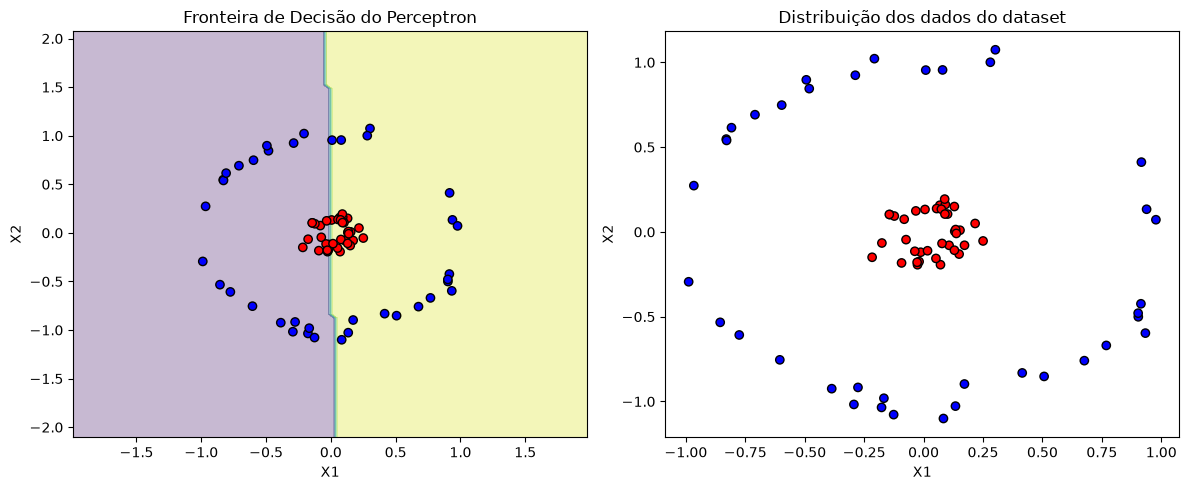

In [37]:
# Dataset 2 - Importando e visualizando o dataset de TESTE
test_dataset2 = np.loadtxt("test_dataset2.csv", delimiter=",", skiprows=1, dtype=float)

# Definição das entradas
X_test = test_dataset2[: , :2] # As duas primeiras colunas são os atributos (X1 e X2)
y_test = test_dataset2[:, 2] # Terceira coluna (rótulos)

# Converter rótulos para -1 e 1 (caso estejam diferentes)
y_test = np.where(y_test == -1, -1, 1)

# Fazer previsões
perceptron.predict2(X_test, y, y_test)

# Plot dos gráficos lado a lado
plot_comparision(X_test, y_test, perceptron)

## Treinando o Perceptron com os dados do Dataset 3
 
| #  | Taxa de Aprendizado | Épocas |
|----|---------------------|--------|
| 1  | 0.1               | 100    |
| 2  | 0.1               | 200    |
| 3  | 0.001             | 100    |
| 4  | 0.001             | 200    |
| 5  | 0.0001            | 100    |
| 6  | 0.0001            | 200    |

Cenário 1 - Treinamento:0.1 | Épocas 100

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 92.52%
Número total de épocas: 100
Pesos finais aprendidos: [-0.02014176 -0.09533053 -0.019518   -0.20101433  0.2566101  -0.13091165
  0.18827028  0.06491732 -0.17627911  1.32344209]
Bias Final: 0.10000000000000003



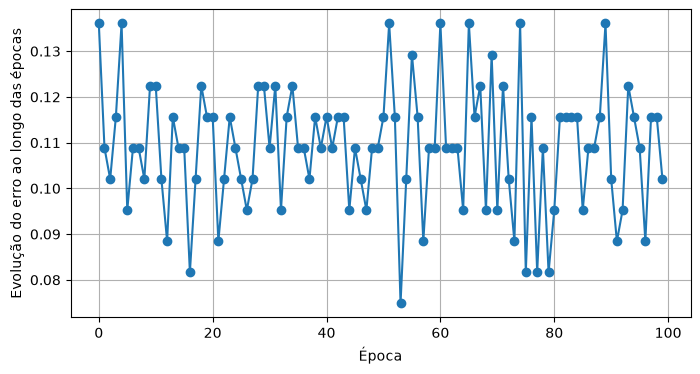


Cenário 2 - Treinamento:0.1 | Épocas 200

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 91.84%
Número total de épocas: 200
Pesos finais aprendidos: [ 0.0291345  -0.20245235 -0.23449194 -0.05212986  0.22064546  0.06338907
  0.08297691 -0.01326432  0.08494198  1.08512717]
Bias Final: 0.20000000000000004



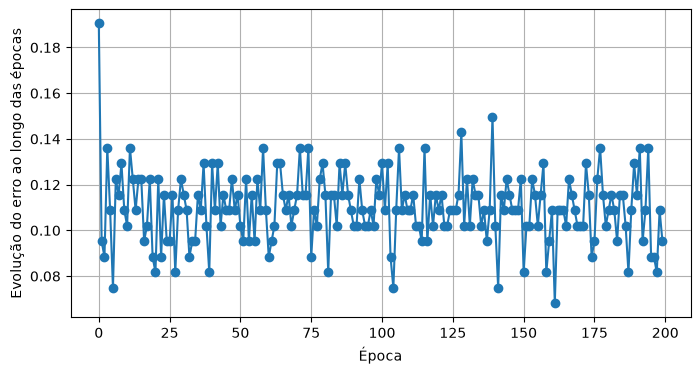


Cenário 3 - Treinamento:0.001 | Épocas 100

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 93.88%
Número total de épocas: 100
Pesos finais aprendidos: [ 4.32919625e-02  8.70932716e-02 -1.22853328e-01  1.81798240e-04
 -1.94001650e-02 -3.93074982e-02  1.41966907e-01  2.86030146e-01
 -8.31214928e-02  7.94476117e-01]
Bias Final: -0.02600000000000001



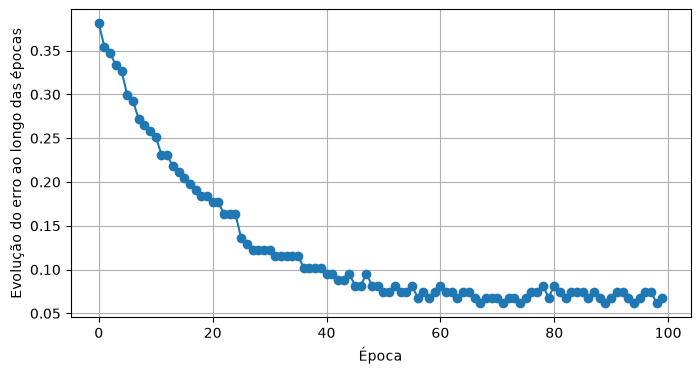


Cenário 4 - Treinamento:0.001 | Épocas 200

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 92.52%
Número total de épocas: 200
Pesos finais aprendidos: [ 0.11840151 -0.00098218 -0.17845407 -0.07441927  0.02670953 -0.04025472
  0.12935675  0.2310901  -0.02575648  0.71395007]
Bias Final: 0.04900000000000006



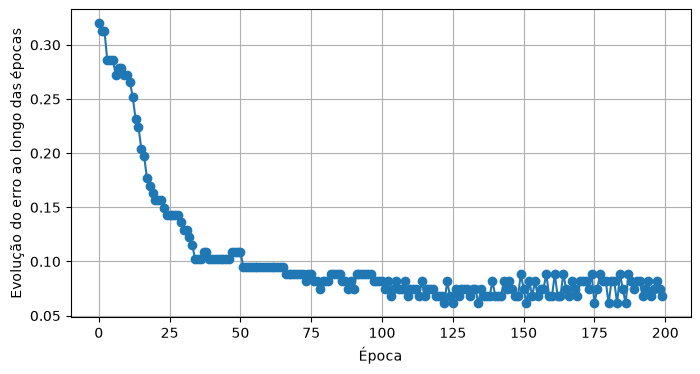


Cenário 5 - Treinamento:0.0001 | Épocas 100

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 73.47%
Número total de épocas: 100
Pesos finais aprendidos: [0.63772439 0.66798965 0.61607107 0.54882571 0.12133996 0.26841535
 0.71693938 0.19187842 0.21682648 1.03804713]
Bias Final: -0.10010000000000184



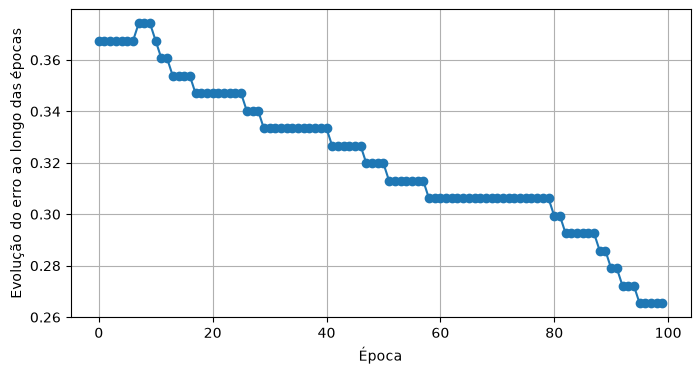


Cenário 6 - Treinamento:0.0001 | Épocas 200

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 82.31%
Número total de épocas: 200
Pesos finais aprendidos: [ 0.11360546  0.24451486 -0.05097551  0.46956293  0.28676035  0.14653693
  0.61100415  0.50710661  0.01996458  0.93461257]
Bias Final: -0.09060000000000157



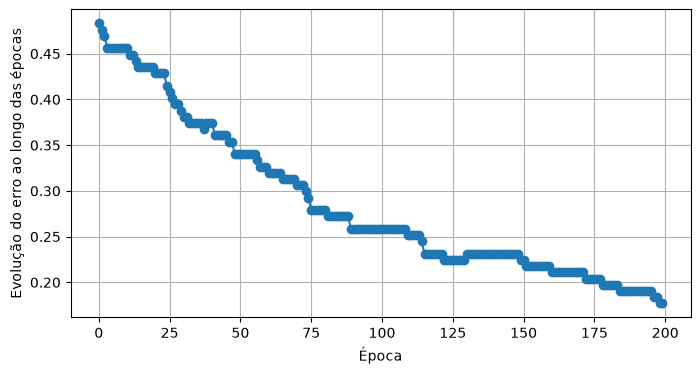

In [39]:
# Dataset 3
train_dataset3 = np.loadtxt("train_dataset3.csv", delimiter=",", skiprows=1, dtype=float)

X = train_dataset3[:, :-1]
y = train_dataset3[:, -1]

y = np.where(y == -1, -1, 1)

perceptron_cenario1 = Perceptron(learning_rate=0.1, n_epochs=100)
perceptron_cenario2 = Perceptron(learning_rate=0.1, n_epochs=200)
perceptron_cenario3 = Perceptron(learning_rate=0.001, n_epochs=100)
perceptron_cenario4 = Perceptron(learning_rate=0.001, n_epochs=200)
perceptron_cenario5 = Perceptron(learning_rate=0.0001, n_epochs=100)
perceptron_cenario6 = Perceptron(learning_rate=0.0001, n_epochs=200)

print("Cenário 1 - Treinamento:0.1 | Épocas 100")
perceptron_cenario1.fit(X, y)
perceptron_cenario1.plot_error()
print("")

print("Cenário 2 - Treinamento:0.1 | Épocas 200")
perceptron_cenario2.fit(X, y)
perceptron_cenario2.plot_error()
print("")

print("Cenário 3 - Treinamento:0.001 | Épocas 100")
perceptron_cenario3.fit(X, y)
perceptron_cenario3.plot_error()
print("")

print("Cenário 4 - Treinamento:0.001 | Épocas 200")
perceptron_cenario4.fit(X, y)
perceptron_cenario4.plot_error()
print("")

print("Cenário 5 - Treinamento:0.0001 | Épocas 100")
perceptron_cenario5.fit(X, y)
perceptron_cenario5.plot_error()
print("")

print("Cenário 6 - Treinamento:0.0001 | Épocas 200")
perceptron_cenario6.fit(X, y)
perceptron_cenario6.plot_error()
print("")

In [40]:
# Dataset 3
test_dataset3 = np.loadtxt("test_dataset3.csv", delimiter=",", skiprows=1, dtype=float)

X_test = test_dataset3[:, :-1]
y_test = test_dataset3[:, -1]

y_test = np.where(y_test == -1, -1, 1)

print("Cenário 1 - Treinamento:0.1 | Épocas 100")
perceptron_cenario1.predict2(X_test, y, y_test)
print("")

print("Cenário 2 - Treinamento:0.1 | Épocas 200")
perceptron_cenario2.predict2(X_test, y, y_test)
print("")

print("Cenário 3 - Treinamento:0.001 | Épocas 100")
perceptron_cenario3.predict2(X_test, y, y_test)
print("")

print("Cenário 4 - Treinamento:0.001 | Épocas 200")
perceptron_cenario4.predict2(X_test, y, y_test)
print("")

print("Cenário 5 - Treinamento:0.0001 | Épocas 100")
perceptron_cenario5.predict2(X_test, y, y_test)
print("")

print("Cenário 6 - Treinamento:0.0001 | Épocas 200")
perceptron_cenario6.predict2(X_test, y, y_test)
print("")

Cenário 1 - Treinamento:0.1 | Épocas 100

===== Resumo do Teste =====
Acurácia no conjunto de teste: 84.13%
Desvio Padrão dos Pesos: 0.42590
Pesos finais aprendidos: [-0.02014176 -0.09533053 -0.019518   -0.20101433  0.2566101  -0.13091165
  0.18827028  0.06491732 -0.17627911  1.32344209]
Bias final: 0.10000000000000003


Cenário 2 - Treinamento:0.1 | Épocas 200

===== Resumo do Teste =====
Acurácia no conjunto de teste: 80.95%
Desvio Padrão dos Pesos: 0.35083
Pesos finais aprendidos: [ 0.0291345  -0.20245235 -0.23449194 -0.05212986  0.22064546  0.06338907
  0.08297691 -0.01326432  0.08494198  1.08512717]
Bias final: 0.20000000000000004


Cenário 3 - Treinamento:0.001 | Épocas 100

===== Resumo do Teste =====
Acurácia no conjunto de teste: 85.71%
Desvio Padrão dos Pesos: 0.25458
Pesos finais aprendidos: [ 4.32919625e-02  8.70932716e-02 -1.22853328e-01  1.81798240e-04
 -1.94001650e-02 -3.93074982e-02  1.41966907e-01  2.86030146e-01
 -8.31214928e-02  7.94476117e-01]
Bias final: -0.0260000